# Camera Calibration Evaluation

In [1]:
import json
from analysis.data_preprocessing import *
from analysis.camera_calibration import *
from segmentation.segmenter import *
from analysis.camera_calibration import * 
from segmentation.segmenter import *
from PIL import Image
import pandas as pd
import os
from tqdm.notebook import tqdm
import math



Welcome to CellposeSAM, cellpose v
cellpose version: 	4.0.4 
platform:       	linux 
python version: 	3.11.11 
torch version:  	2.7.0+cu126! The neural network component of
CPSAM is much larger than in previous versions and CPU excution is slow. 
We encourage users to use GPU/MPS if available. 




### Data and Experiment Setup

In [2]:
chip_region = 2
EXPERIMENT_CONFIG = {
    "chip_region": chip_region,
    "data_dir": "../../data/Raw/Chip2-NaCl 0-19_",           # str, Image directory
    "image_batch": f"290-4-0.75x-{chip_region}",                          # str, Specific image batch, e.g. 290-4-0.75x-3
    "zoom": 0.75,                                            # float, Camera zoom
    "cc": False,                                              # bool, Use camera calibration
    "ffc": False,                                             # bool, Use flatfield correction
    "clahe": False,                                          # bool, Use clahe (for segmentation only)
    "model": "SAM2",                                         # str, SAM2 or CellposeSAM
    "approx": False,                                          # bool, Use approximated masks
    "approx_method": "ellipse",                              # str, "circle" or "ellipse"
    "overlay_masks": False,                                  # bool, use masks from first image on all following images
    "individual_intensities": False,                         # bool, show individual intensity points on intensity plots and link to segmentation results
    "filter_config": {
        "circularity_threshold": 0.7,
        "border_thres": 2,
        "max_groups": 2 if chip_region == 2 else 3,
        "eps_area": 40, 
        "eps_coords_medium": 90,
        "eps_coords_small": 70,
        "eps_coords_small_exclude": 20,
        "rough_only": False,
        "debug": False
    },
    "calibrator_config": {
        "ref_radii": {
            "region1": 500, # use large wells
            "region2": 175, # use medium wells - why is 250 too large?
            "region3": 500 # use large wells
        },
        "schematic_path1": "../../data/Raw/Chip-schematic/chip_cleaned_1_10.jpg",
        "schematic_path2": "../../data/Raw/Chip-schematic/chip_cleaned_2_8.jpg",
        "schematic_path3": "../../data/Raw/Chip-schematic/chip_cleaned_3_10.jpg",
        "calculate_individual": True
    },
    "debug": True
}

# Collect the right images from the specified directory and group them in batches of increasing NaCl concentration
data = data_preprocessing(EXPERIMENT_CONFIG["data_dir"], EXPERIMENT_CONFIG["image_batch"])

# Isolate the specified batch as a list of dictionaries
data = data[EXPERIMENT_CONFIG["image_batch"] + ".jpg"]

print(json.dumps(data, indent=4))

[
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-0_-2.jpg",
        "nacl_percentage": 0.0
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-1,3_-2.jpg",
        "nacl_percentage": 1.3
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-2,6_-2.jpg",
        "nacl_percentage": 2.6
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-3,9_-2.jpg",
        "nacl_percentage": 3.9
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-5,2_-2.jpg",
        "nacl_percentage": 5.2
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-6,5_-2.jpg",
        "nacl_percentage": 6.5
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-10,4_-2.jpg",
        "nacl_percentage": 10.4
    },
    {
        "file_path": "../../data/Raw/Chip2-NaCl 0-19_/290-4-0,75x-14,7_-2.jpg",
        "nacl_percentage": 14.7
    },
    {
      

### Object Setup

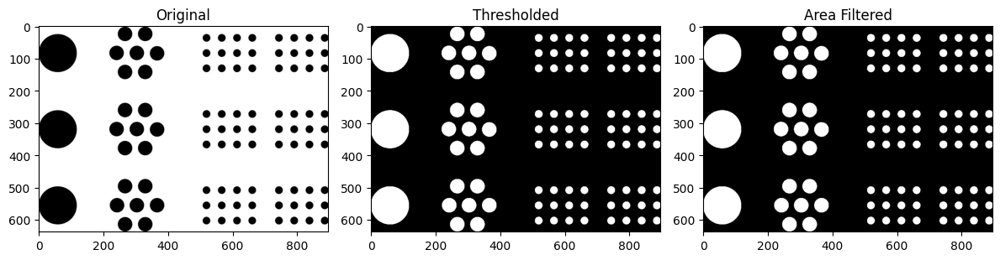

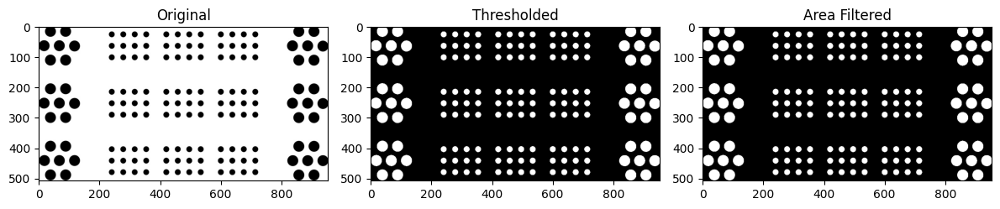

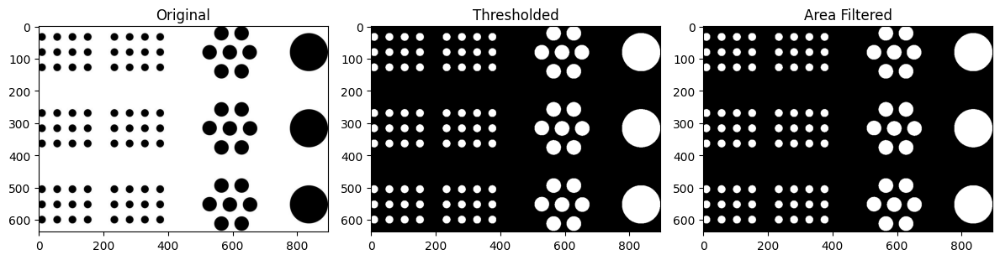

In [3]:
# Camera
camera = Camera(
    zoom=EXPERIMENT_CONFIG["zoom"],
    um_per_pixel=6.45
)

# Segmenter
finetuned_checkpoint = "../../models/Train81_200E_b+_like_sa1b/checkpoints/checkpoint.pt"
model_cfg_b_plus = "configs/sam2.1/sam2.1_hiera_b+.yaml"
sam2 = SAM2Wrapper(config=model_cfg_b_plus, checkpoint=finetuned_checkpoint, points_per_side=128)
cellposeSAM = CellposeSAMWrapper()
segmenter = Segmenter(model=sam2, filter_config=EXPERIMENT_CONFIG["filter_config"])

# Calibrator
setup_image_path = data[0]["file_path"]
setup_image = np.array(Image.open(setup_image_path).convert('L'))

schematic_path1 = EXPERIMENT_CONFIG["calibrator_config"]["schematic_path1"] 
schematic_raw1 = np.array(Image.open(schematic_path1).convert('L'))
schematic_mask1 = extract_schematic(image=schematic_raw1, debug=EXPERIMENT_CONFIG["debug"])
schematic_path2 = EXPERIMENT_CONFIG["calibrator_config"]["schematic_path2"] 
schematic_raw2 = np.array(Image.open(schematic_path2).convert('L'))
schematic_mask2 = extract_schematic(image=schematic_raw2, debug=EXPERIMENT_CONFIG["debug"])
schematic_path3 = EXPERIMENT_CONFIG["calibrator_config"]["schematic_path3"] 
schematic_raw3 = np.array(Image.open(schematic_path3).convert('L'))
schematic_mask3 = extract_schematic(image=schematic_raw3, debug=EXPERIMENT_CONFIG["debug"])
ref_images = {
    "region1": schematic_mask1,
    "region2": schematic_mask2,
    "region3": schematic_mask3,
}

calibrator = CameraCalibrator(
    setup_image=setup_image,
    camera=camera,
    segmenter=segmenter,
    ref_images=ref_images,
    ref_radii=EXPERIMENT_CONFIG["calibrator_config"]["ref_radii"],
    calculate_individual=EXPERIMENT_CONFIG["calibrator_config"]["calculate_individual"]
)

### Run Experiment

  0%|          | 0/9 [00:00<?, ?it/s]

==== Evaluating camera calibration for image 290-4-0,75x-0_-2. ====
[generate_masks] executed in 9.4266 seconds
[filter_masks] executed in 3.8592 seconds


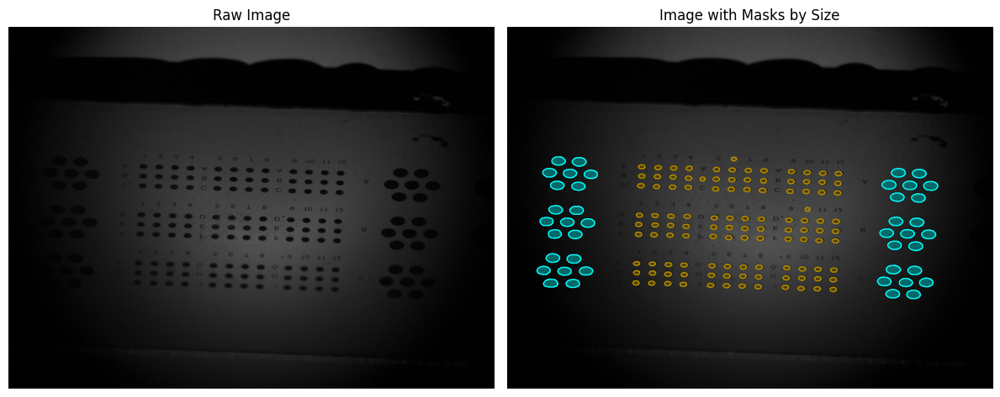

[visualize_masks_by_well_size] executed in 1.3503 seconds
[_calculate_affine_transform] executed in 0.0003 seconds
[generate_masks] executed in 8.4473 seconds
[filter_masks] executed in 3.0825 seconds


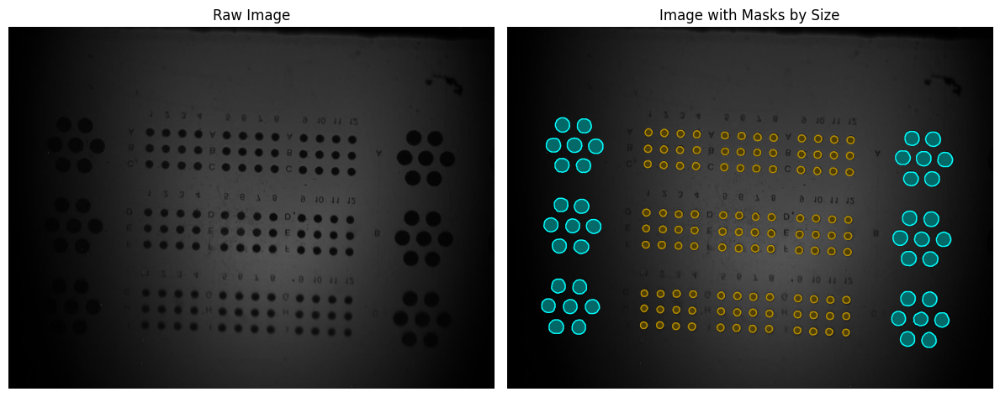

[visualize_masks_by_well_size] executed in 1.3057 seconds


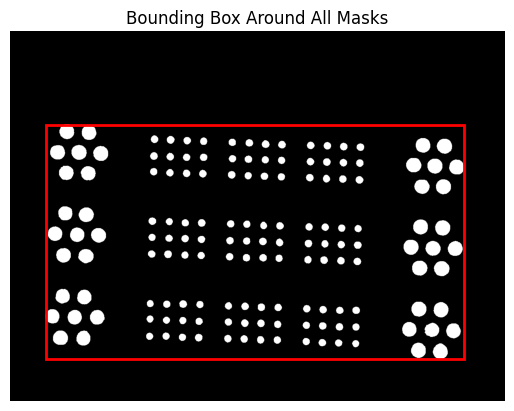

Translation: [75.17239076 -6.8110608 ]
Scale: 0.9911305751597795
Rotation: -1.4501395420392384°


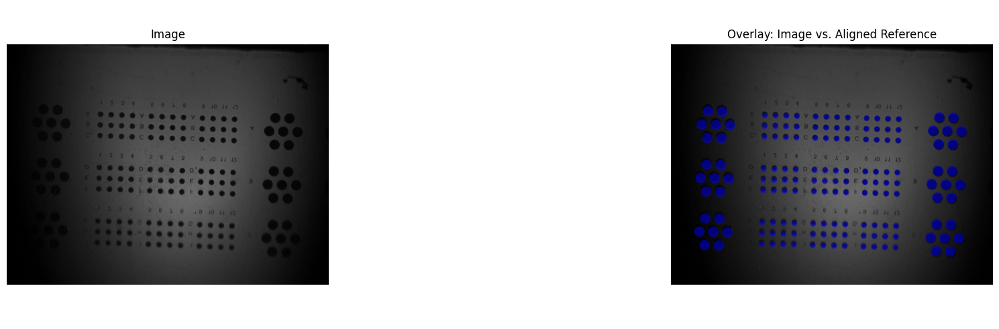

[_apply_imreg_dft] executed in 7.6975 seconds
[generate_masks] executed in 8.6233 seconds
[filter_masks] executed in 2.9810 seconds
[find_overlapping_pairs] executed in 0.4634 seconds
Src: 150, Dst: 150
[_match_centroids] executed in 12.8587 seconds


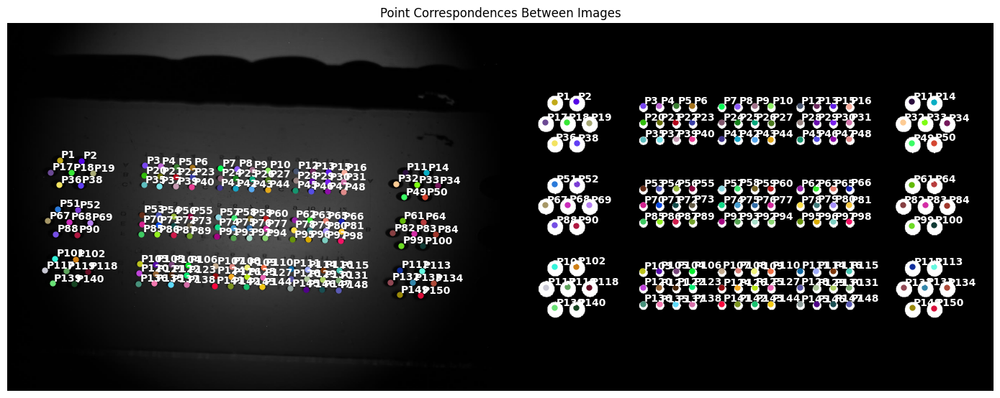

[calculate_homography] executed in 21.0245 seconds
[undistort] executed in 48.8459 seconds


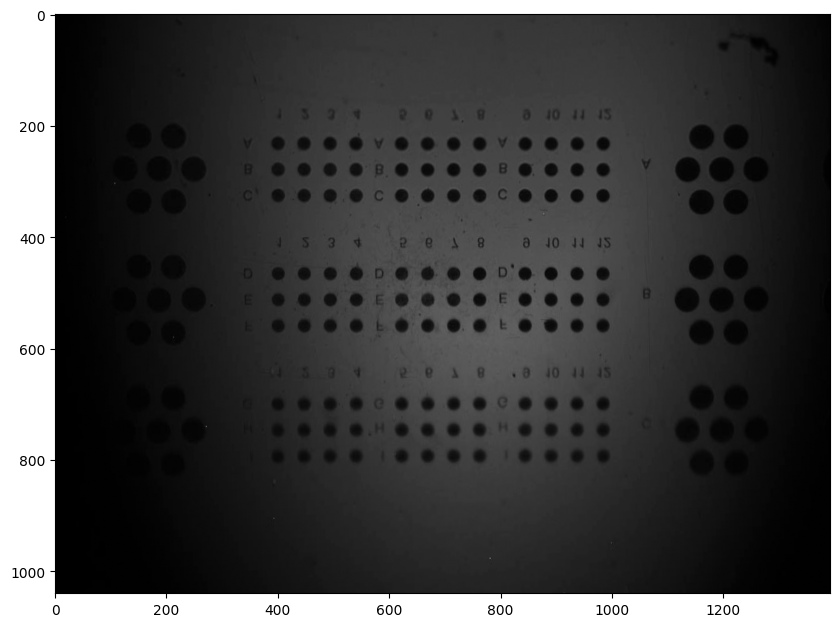

Translation: [75.17239076 -6.8110608 ]
Scale: 0.9911305751597795
Rotation: -1.4501395420392384°


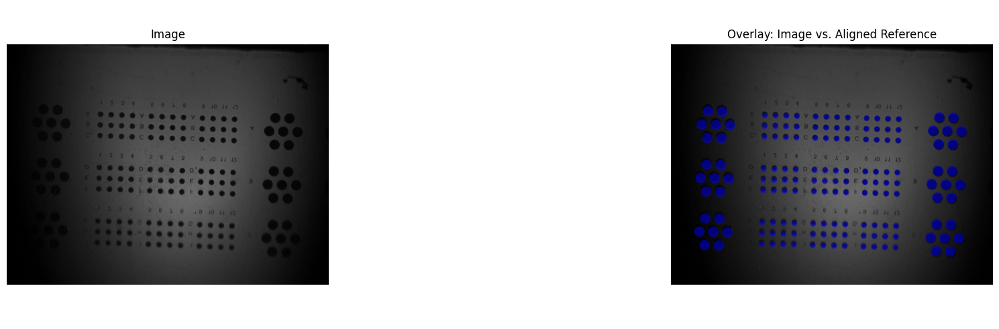

[generate_masks] executed in 8.3935 seconds
[filter_masks] executed in 3.0239 seconds
[filter_overlapping_masks] executed in 0.4800 seconds
Num overlaps:  150
[filter_overlapping_masks] executed in 0.0672 seconds
[filter_overlapping_masks] executed in 0.4020 seconds
Average IoU all: 0.6367407510010401
Average IoU large: 0
Average IoU medium: 0.684206912359218
Average IoU small: 0.6182816882506373
[evaluate_camera_calibration] executed in 21.5740 seconds
Translation: [-6.02613548 -3.28286531]
Scale: 0.9997203405998352
Rotation: -0.03427119882212537°


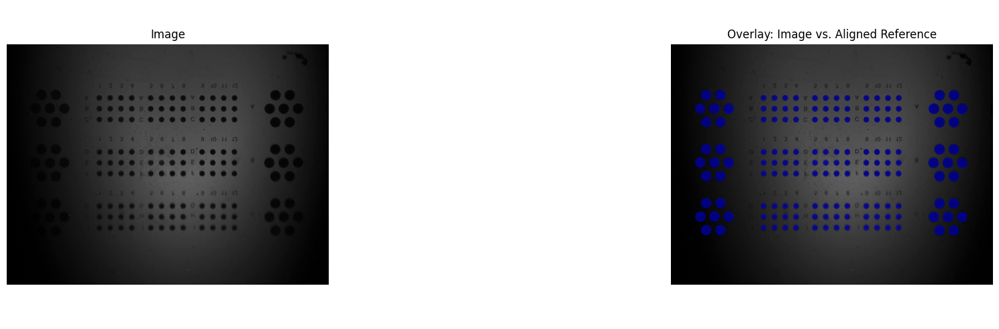

[generate_masks] executed in 8.2729 seconds
[filter_masks] executed in 2.9307 seconds
[filter_overlapping_masks] executed in 0.4833 seconds
Num overlaps:  150
[filter_overlapping_masks] executed in 0.0804 seconds
[filter_overlapping_masks] executed in 0.4037 seconds
Average IoU all: 0.879562003909617
Average IoU large: 0
Average IoU medium: 0.8984460628584221
Average IoU small: 0.872218203207304
[evaluate_camera_calibration] executed in 21.4289 seconds
==== Evaluating camera calibration for image 290-4-0,75x-1,3_-2. ====
Translation: [75.01473013 -7.6367863 ]
Scale: 0.9899554545942857
Rotation: -1.5980152508574577°


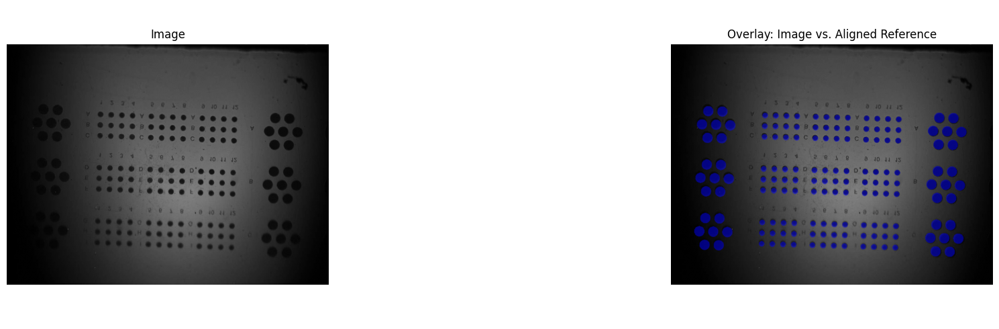

[_apply_imreg_dft] executed in 5.9124 seconds
[generate_masks] executed in 8.2642 seconds
[filter_masks] executed in 2.9929 seconds
[find_overlapping_pairs] executed in 0.4740 seconds
Src: 150, Dst: 150
[_match_centroids] executed in 12.2514 seconds


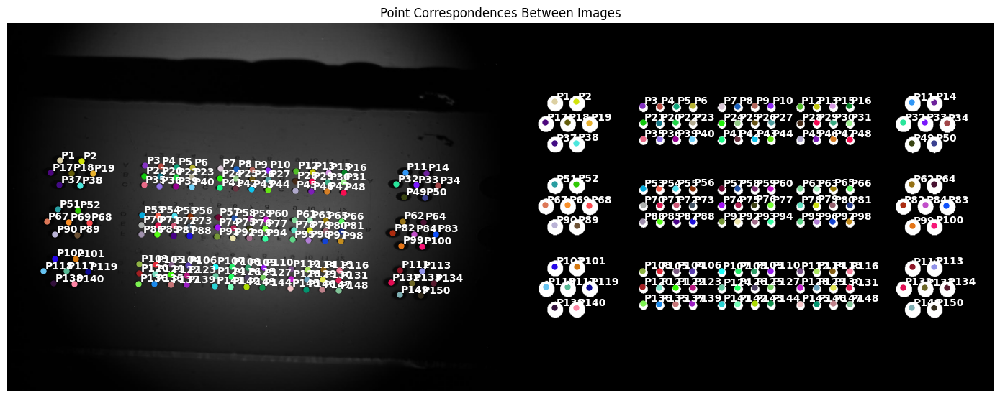

[calculate_homography] executed in 18.6189 seconds
[undistort] executed in 18.6274 seconds


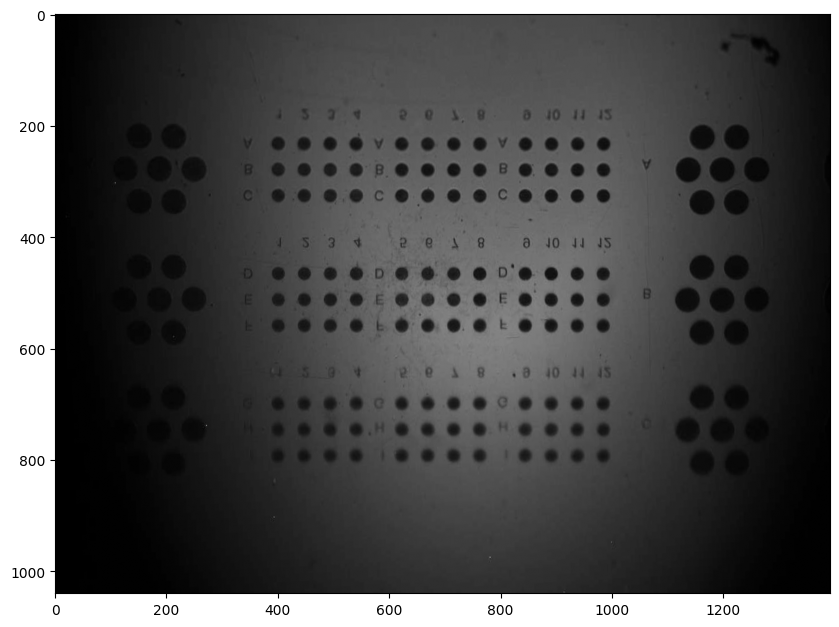

Translation: [75.01473013 -7.6367863 ]
Scale: 0.9899554545942857
Rotation: -1.5980152508574577°


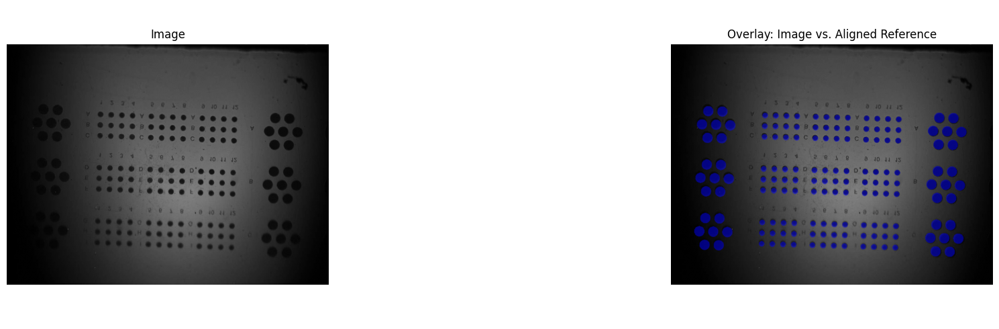

[generate_masks] executed in 8.2941 seconds
[filter_masks] executed in 2.9325 seconds
[filter_overlapping_masks] executed in 0.4635 seconds
Num overlaps:  150
[filter_overlapping_masks] executed in 0.0675 seconds
[filter_overlapping_masks] executed in 0.4015 seconds
Average IoU all: 0.6289594080025709
Average IoU large: 0
Average IoU medium: 0.7001152039071229
Average IoU small: 0.6012877095952456
[evaluate_camera_calibration] executed in 21.4420 seconds
Translation: [-5.91986799 -2.75757882]
Scale: 1.0000606728345731
Rotation: -0.09742506111632565°


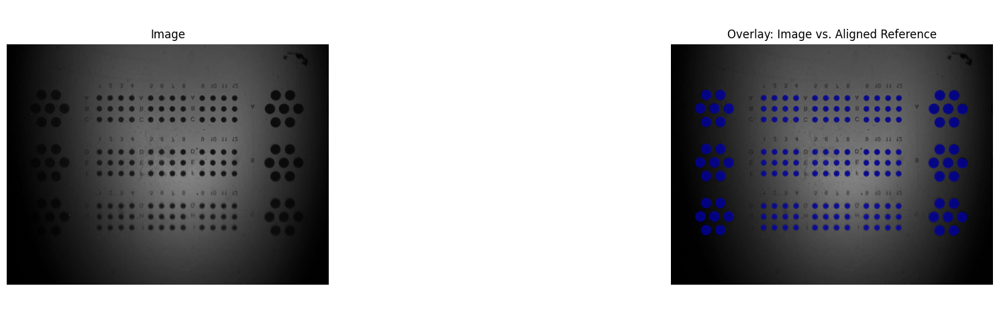

[generate_masks] executed in 8.3720 seconds
[filter_masks] executed in 3.3697 seconds
[filter_overlapping_masks] executed in 0.5117 seconds
Num overlaps:  150
[filter_overlapping_masks] executed in 0.0673 seconds
[filter_overlapping_masks] executed in 0.4512 seconds
Average IoU all: 0.8552269371637542
Average IoU large: 0
Average IoU medium: 0.8928993675241631
Average IoU small: 0.840576547579151
[evaluate_camera_calibration] executed in 24.3684 seconds
==== Evaluating camera calibration for image 290-4-0,75x-2,6_-2. ====
Translation: [ 77.05975891 -11.93148606]
Scale: 0.9915365940721889
Rotation: -1.5428689669443827°


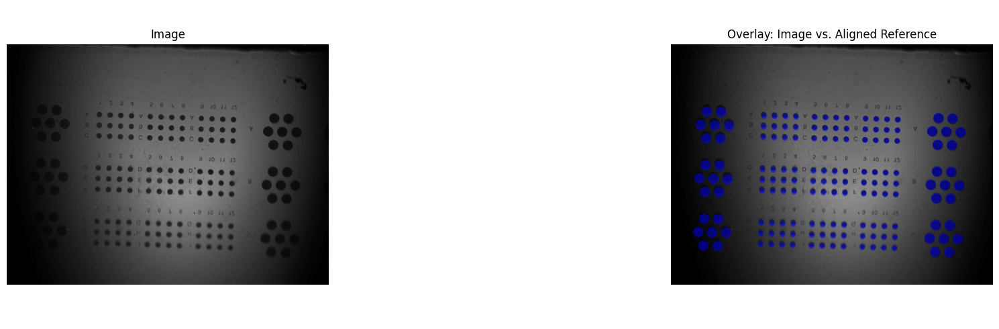

[_apply_imreg_dft] executed in 5.9024 seconds
[generate_masks] executed in 8.3013 seconds
[filter_masks] executed in 3.3623 seconds
[find_overlapping_pairs] executed in 0.5190 seconds
Src: 150, Dst: 150
[_match_centroids] executed in 12.6763 seconds


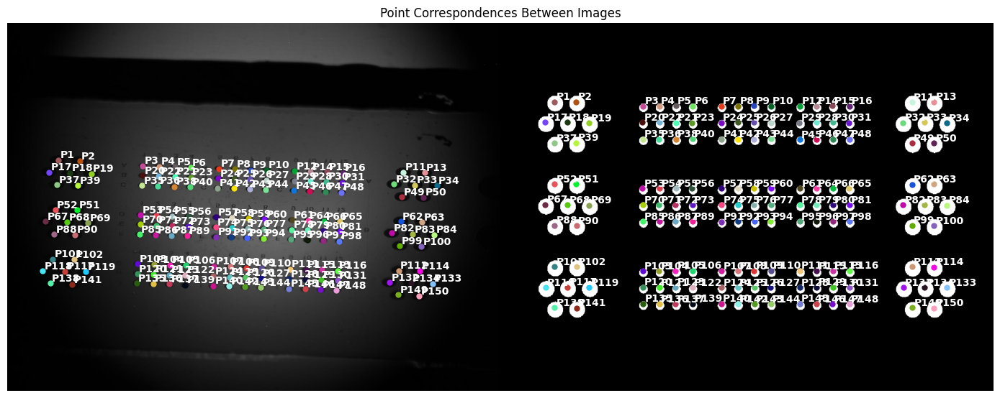

[calculate_homography] executed in 19.0670 seconds
[undistort] executed in 19.0752 seconds


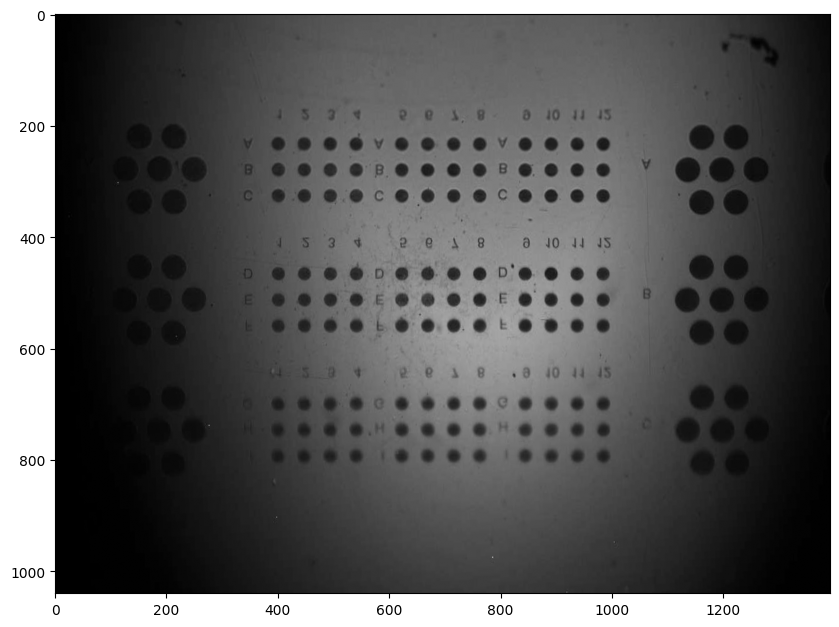

Translation: [ 77.05975891 -11.93148606]
Scale: 0.9915365940721889
Rotation: -1.5428689669443827°


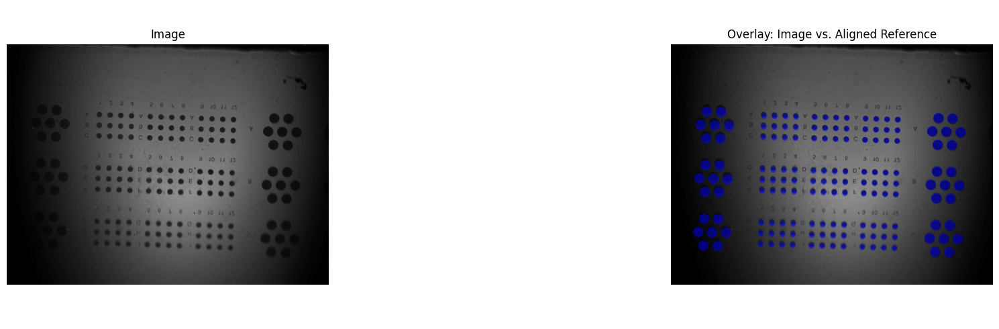

[generate_masks] executed in 8.3866 seconds
[filter_masks] executed in 3.3142 seconds
[filter_overlapping_masks] executed in 0.4846 seconds
Num overlaps:  150
[filter_overlapping_masks] executed in 0.0674 seconds
[filter_overlapping_masks] executed in 0.3985 seconds
Average IoU all: 0.5795328379422117
Average IoU large: 0
Average IoU medium: 0.6964776221950566
Average IoU small: 0.5340543107327721
[evaluate_camera_calibration] executed in 21.8924 seconds
Translation: [-5.92595049 -3.12660347]
Scale: 0.9992878232774652
Rotation: -0.07022143962808514°


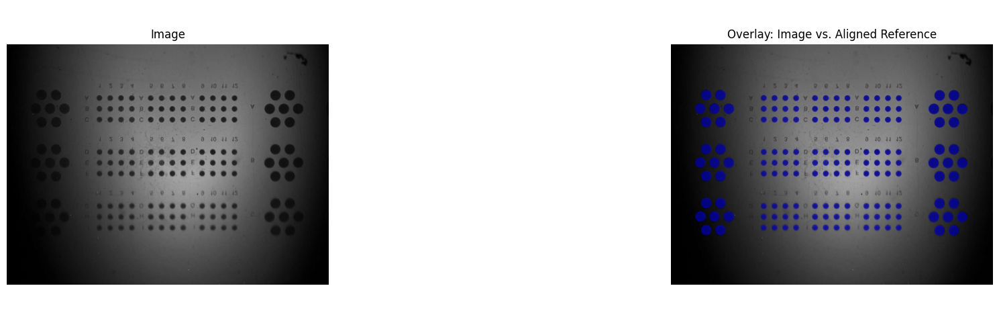

[generate_masks] executed in 8.5590 seconds
[filter_masks] executed in 3.2491 seconds
[filter_overlapping_masks] executed in 0.4816 seconds
Num overlaps:  150
[filter_overlapping_masks] executed in 0.0674 seconds
[filter_overlapping_masks] executed in 0.4089 seconds
Average IoU all: 0.8284326395566389
Average IoU large: 0
Average IoU medium: 0.8330028790773527
Average IoU small: 0.8266553241874719
[evaluate_camera_calibration] executed in 22.0182 seconds
==== Evaluating camera calibration for image 290-4-0,75x-3,9_-2. ====
Translation: [79.86531643 90.04156878]
Scale: 0.9907044025516358
Rotation: -1.630497527448398°


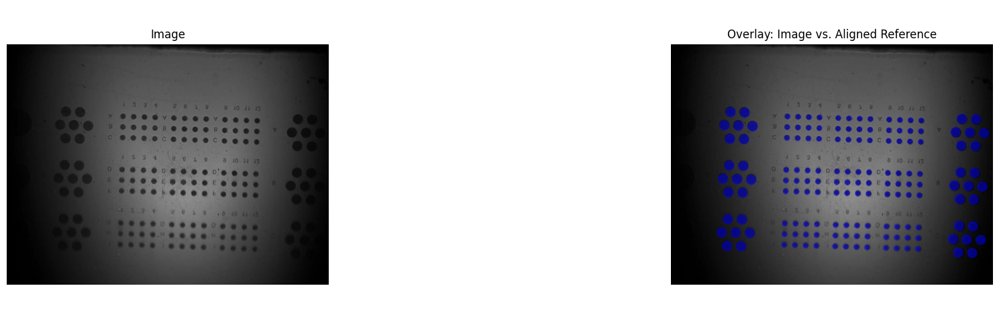

[_apply_imreg_dft] executed in 5.8426 seconds
[generate_masks] executed in 8.2549 seconds
[filter_masks] executed in 3.6180 seconds
[find_overlapping_pairs] executed in 0.4804 seconds
Src: 150, Dst: 150
[_match_centroids] executed in 12.9249 seconds


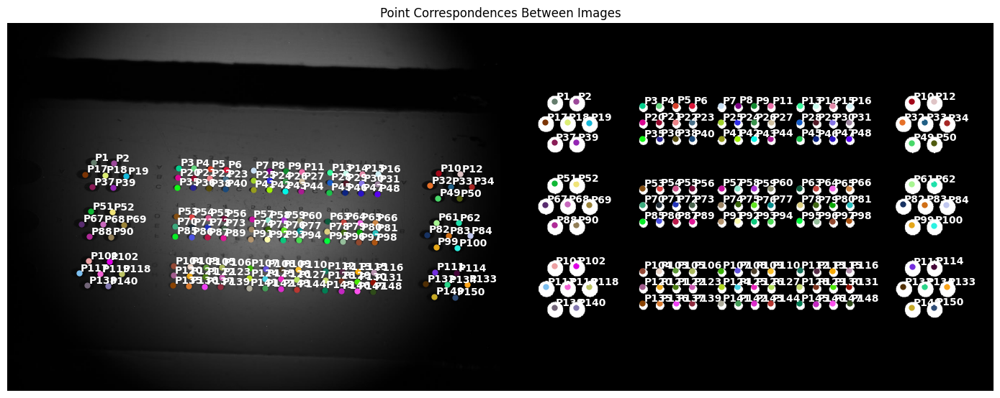

[calculate_homography] executed in 19.2099 seconds
[undistort] executed in 19.2181 seconds


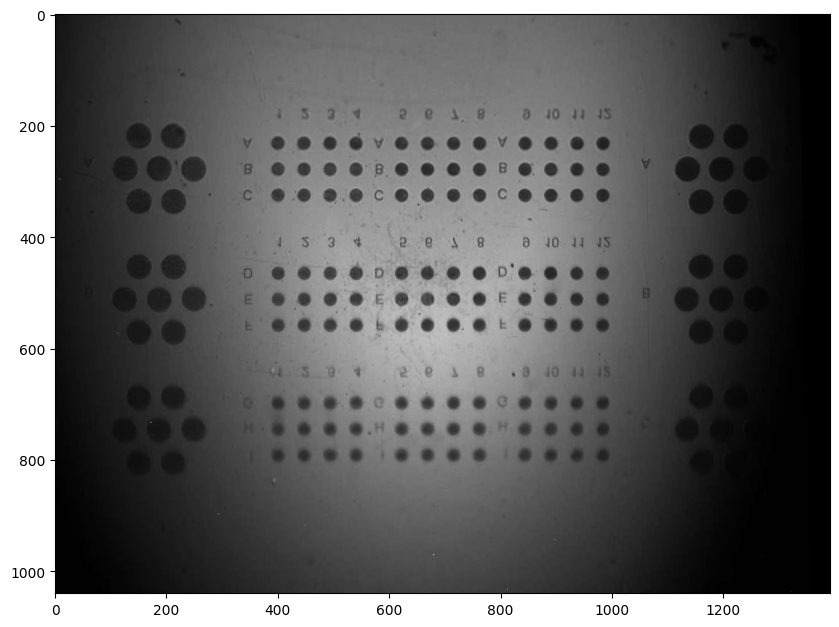

Translation: [79.86531643 90.04156878]
Scale: 0.9907044025516358
Rotation: -1.630497527448398°


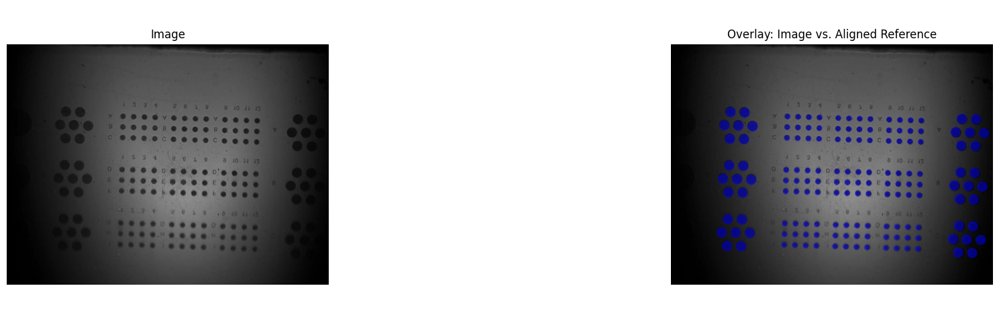

[generate_masks] executed in 8.3200 seconds
[filter_masks] executed in 5.6664 seconds
[filter_overlapping_masks] executed in 0.4780 seconds
Num overlaps:  150
[filter_overlapping_masks] executed in 0.0676 seconds
[filter_overlapping_masks] executed in 0.3890 seconds
Average IoU all: 0.738699228568515
Average IoU large: 0
Average IoU medium: 0.7724014117517942
Average IoU small: 0.72559282399724
[evaluate_camera_calibration] executed in 24.2023 seconds
Translation: [-6.85187371 -3.84105624]
Scale: 0.9995690867604697
Rotation: -0.00540182383073784°


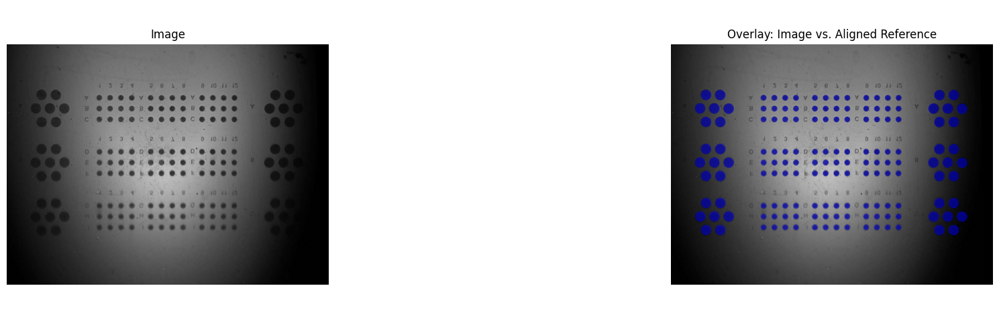

[generate_masks] executed in 8.3250 seconds
[filter_masks] executed in 3.2274 seconds
[filter_overlapping_masks] executed in 0.5572 seconds
Num overlaps:  150
[filter_overlapping_masks] executed in 0.0718 seconds
[filter_overlapping_masks] executed in 0.4172 seconds
Average IoU all: 0.8381885768222717
Average IoU large: 0
Average IoU medium: 0.8674913152560997
Average IoU small: 0.826793067431339
[evaluate_camera_calibration] executed in 21.8217 seconds
==== Evaluating camera calibration for image 290-4-0,75x-5,2_-2. ====
Translation: [ 78.84344982 -19.91402353]
Scale: 0.9907764882059692
Rotation: -1.67044377374242°


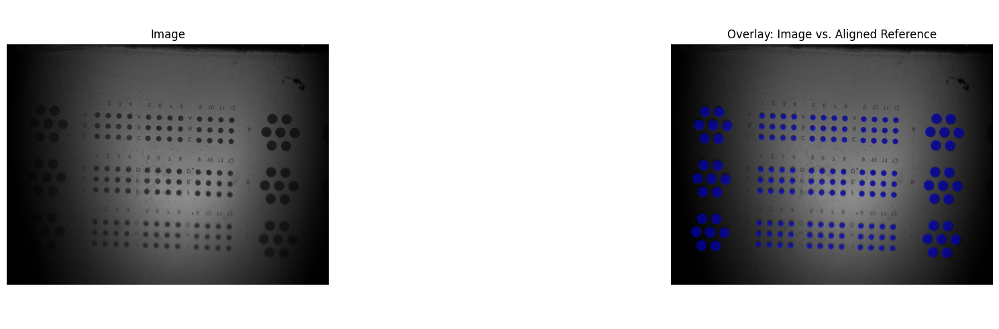

[_apply_imreg_dft] executed in 5.9537 seconds
[generate_masks] executed in 8.2855 seconds
[filter_masks] executed in 3.2331 seconds
[find_overlapping_pairs] executed in 0.4581 seconds
Src: 147, Dst: 147
[_match_centroids] executed in 12.5092 seconds


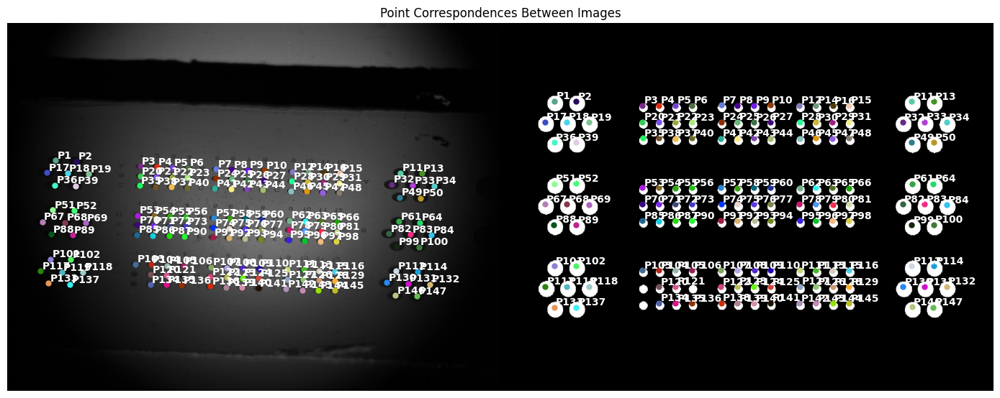

[calculate_homography] executed in 19.1352 seconds
[undistort] executed in 19.1438 seconds


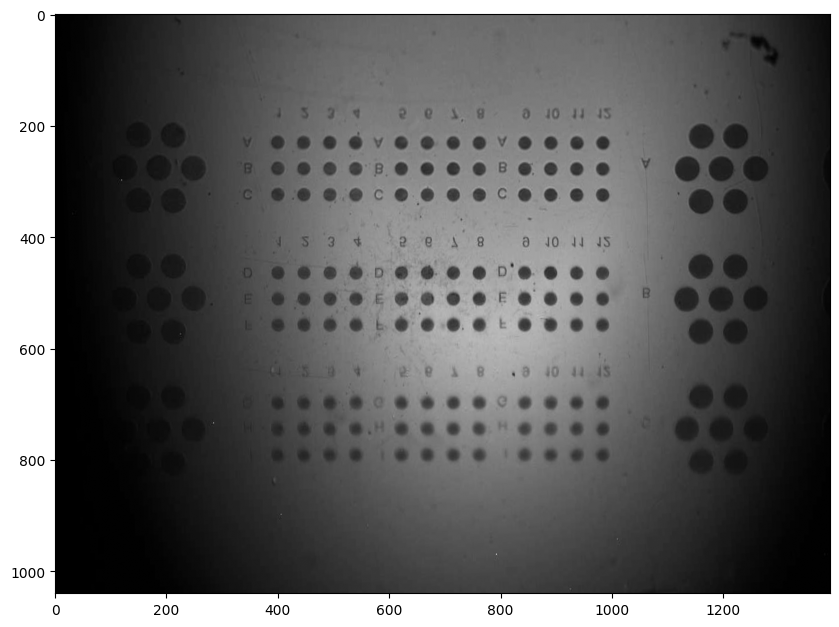

Translation: [ 78.84344982 -19.91402353]
Scale: 0.9907764882059692
Rotation: -1.67044377374242°


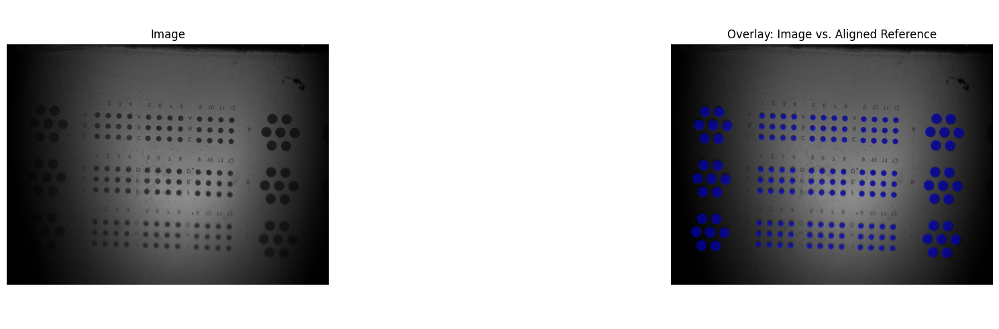

[generate_masks] executed in 8.1709 seconds
[filter_masks] executed in 3.2294 seconds
[filter_overlapping_masks] executed in 0.4679 seconds
Num overlaps:  147
[filter_overlapping_masks] executed in 0.0677 seconds
[filter_overlapping_masks] executed in 0.4232 seconds
Average IoU all: 0.6627587442166928
Average IoU large: 0
Average IoU medium: 0.7151122779206361
Average IoU small: 0.6418173307351158
[evaluate_camera_calibration] executed in 23.6558 seconds
Translation: [-6.97567718 -3.80112233]
Scale: 0.999861659607672
Rotation: -0.08524166539669409°


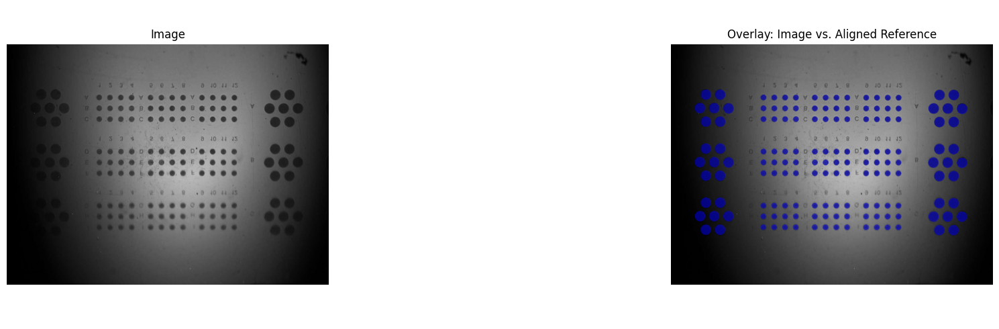

[generate_masks] executed in 9.0458 seconds
[filter_masks] executed in 3.0398 seconds
[filter_overlapping_masks] executed in 0.5023 seconds
Num overlaps:  149
[filter_overlapping_masks] executed in 0.0806 seconds
[filter_overlapping_masks] executed in 0.4348 seconds
Average IoU all: 0.8366409339577784
Average IoU large: 0
Average IoU medium: 0.8853411173510748
Average IoU small: 0.8175249741211573
[evaluate_camera_calibration] executed in 22.4457 seconds
==== Evaluating camera calibration for image 290-4-0,75x-6,5_-2. ====
Translation: [101.00188298 -44.15355554]
Scale: 0.9917121209094185
Rotation: -1.6777627561899067°


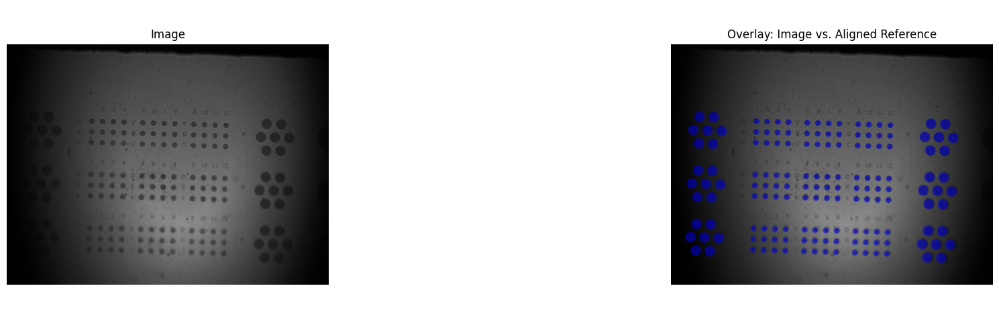

[_apply_imreg_dft] executed in 5.9992 seconds
[generate_masks] executed in 8.2222 seconds
[filter_masks] executed in 3.4783 seconds
[find_overlapping_pairs] executed in 0.4346 seconds
Src: 143, Dst: 143
[_match_centroids] executed in 12.6546 seconds


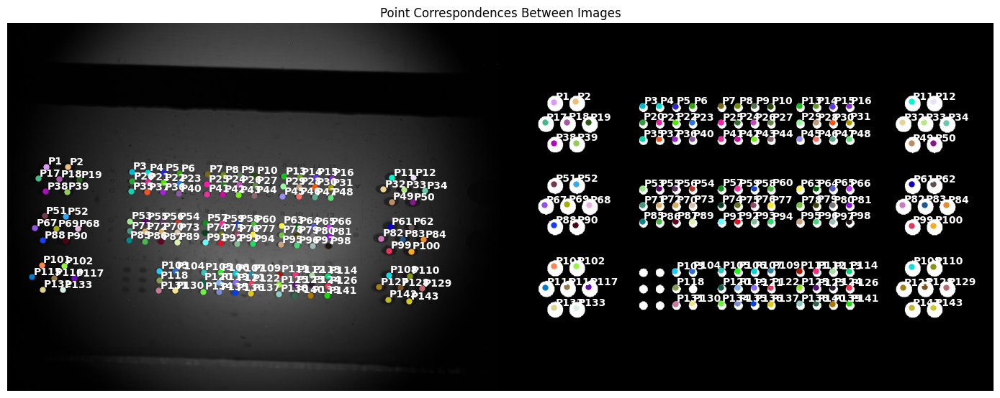

[calculate_homography] executed in 19.3225 seconds
[undistort] executed in 19.3312 seconds


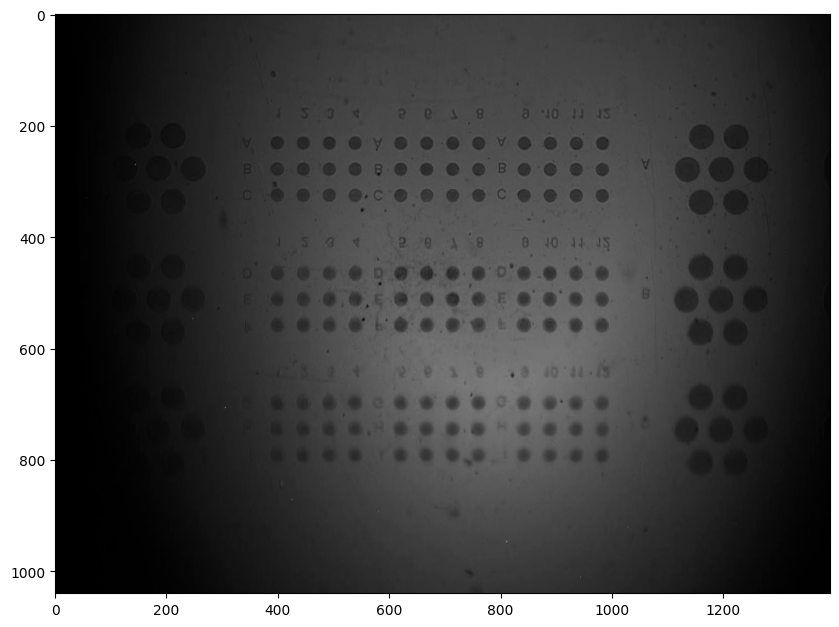

Translation: [101.00188298 -44.15355554]
Scale: 0.9917121209094185
Rotation: -1.6777627561899067°


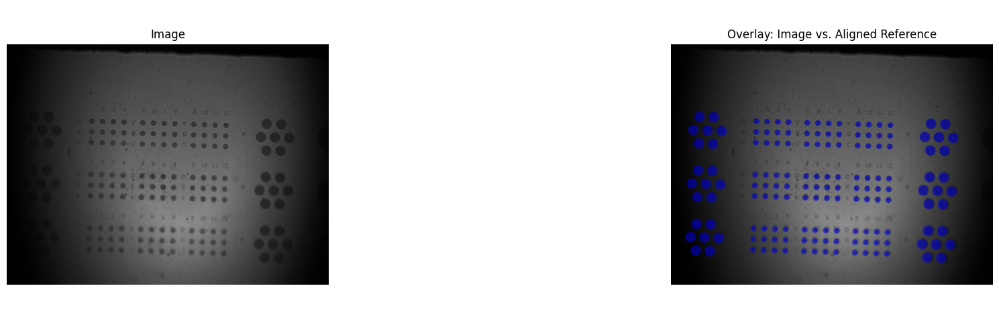

[generate_masks] executed in 8.3395 seconds
[filter_masks] executed in 3.4184 seconds
[filter_overlapping_masks] executed in 0.4321 seconds
Num overlaps:  143
[filter_overlapping_masks] executed in 0.0676 seconds
[filter_overlapping_masks] executed in 0.3587 seconds
Average IoU all: 0.710607799736531
Average IoU large: 0
Average IoU medium: 0.7873811121307152
Average IoU small: 0.6786822638894445
[evaluate_camera_calibration] executed in 22.6436 seconds
Translation: [-6.31666877 -4.85322424]
Scale: 0.9998024976400892
Rotation: -0.046922388770781254°


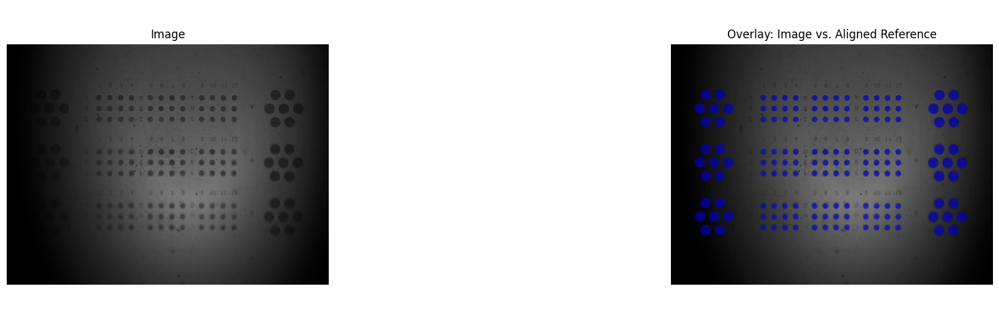

[generate_masks] executed in 8.1552 seconds
[filter_masks] executed in 3.6032 seconds
[filter_overlapping_masks] executed in 0.4751 seconds
Num overlaps:  145
[filter_overlapping_masks] executed in 0.0660 seconds
[filter_overlapping_masks] executed in 0.4633 seconds
Average IoU all: 0.8452293545540901
Average IoU large: 0
Average IoU medium: 0.9082895300839612
Average IoU small: 0.8203690930471217
[evaluate_camera_calibration] executed in 21.9148 seconds
==== Evaluating camera calibration for image 290-4-0,75x-10,4_-2. ====
Translation: [101.16593193  -3.76399827]
Scale: 0.9919683582351088
Rotation: -1.6551590685438384°


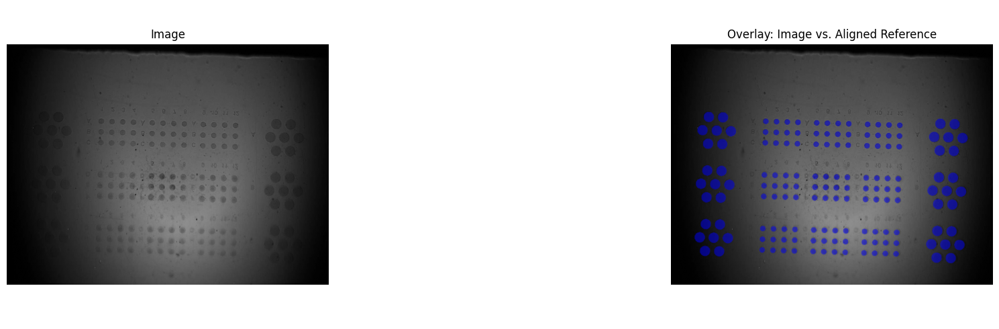

[_apply_imreg_dft] executed in 5.9962 seconds
[generate_masks] executed in 7.9285 seconds
[filter_masks] executed in 2.2466 seconds
[find_overlapping_pairs] executed in 0.3678 seconds
Src: 121, Dst: 121
[_match_centroids] executed in 11.0635 seconds


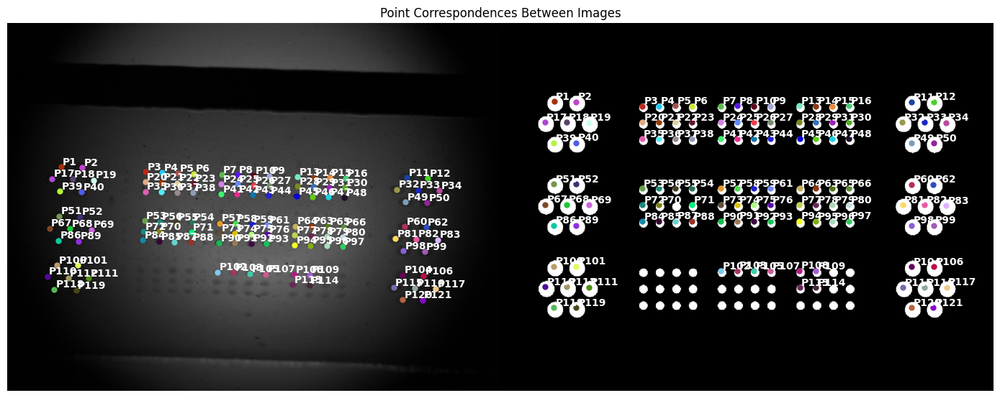

[calculate_homography] executed in 17.4608 seconds
[undistort] executed in 17.4690 seconds


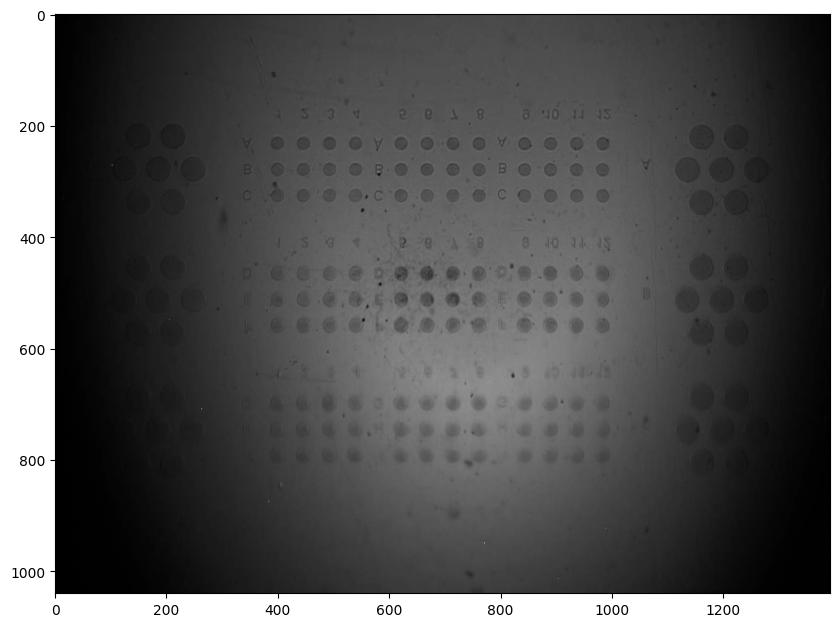

Translation: [101.16593193  -3.76399827]
Scale: 0.9919683582351088
Rotation: -1.6551590685438384°


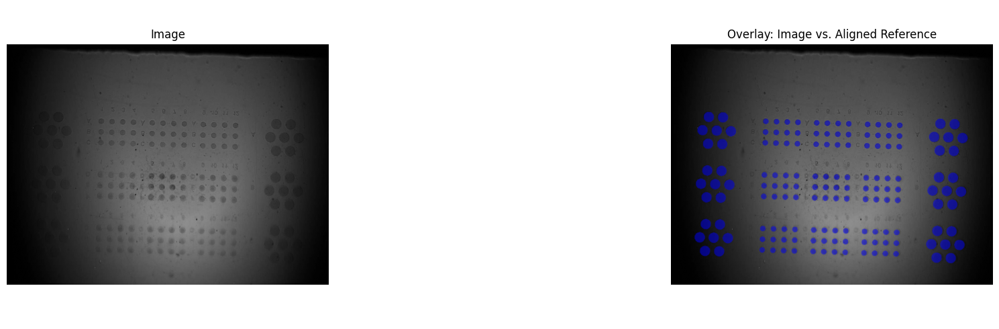

[generate_masks] executed in 7.7558 seconds
[filter_masks] executed in 2.2784 seconds
[filter_overlapping_masks] executed in 0.3594 seconds
Num overlaps:  121
[filter_overlapping_masks] executed in 0.0671 seconds
[filter_overlapping_masks] executed in 0.2777 seconds
Average IoU all: 0.7407583408425995
Average IoU large: 0
Average IoU medium: 0.7703823946390047
Average IoU small: 0.7250088438875496
[evaluate_camera_calibration] executed in 19.3926 seconds
Translation: [-5.2296725  -4.16605281]
Scale: 1.0005622516510397
Rotation: -0.017311833927578846°


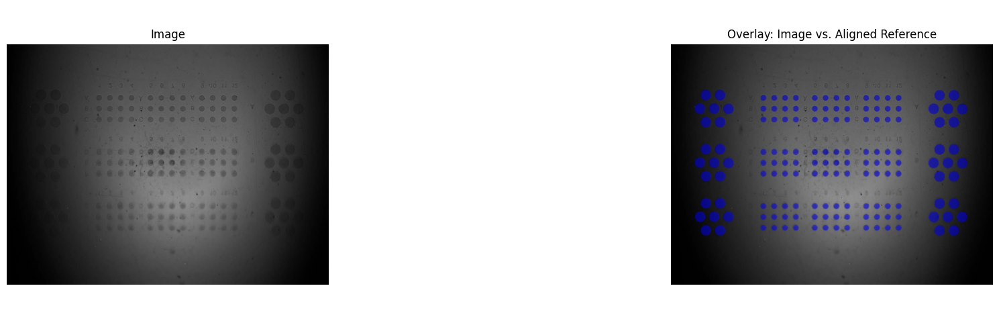

[generate_masks] executed in 7.9221 seconds
[filter_masks] executed in 2.1531 seconds
[filter_overlapping_masks] executed in 0.3724 seconds
Num overlaps:  118
[filter_overlapping_masks] executed in 0.0674 seconds
[filter_overlapping_masks] executed in 0.2770 seconds
Average IoU all: 0.8208120263176145
Average IoU large: 0
Average IoU medium: 0.8255398314767575
Average IoU small: 0.818199291887563
[evaluate_camera_calibration] executed in 19.3461 seconds
==== Evaluating camera calibration for image 290-4-0,75x-14,7_-2. ====
Translation: [102.1184692   45.25883707]
Scale: 0.9927007251310448
Rotation: -1.7215382507895924°


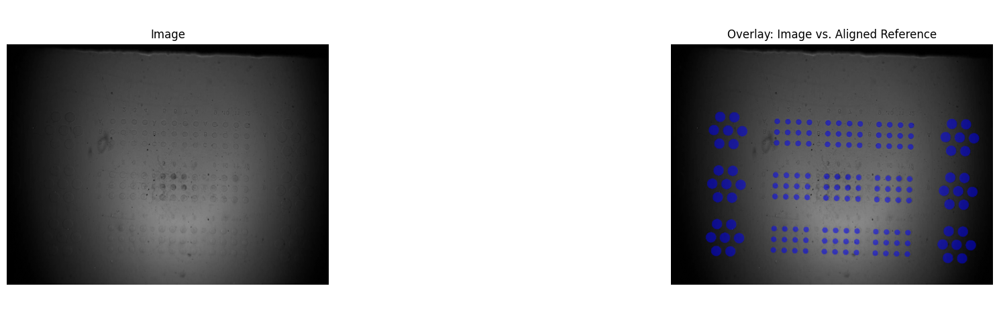

[_apply_imreg_dft] executed in 5.9284 seconds
[generate_masks] executed in 7.5927 seconds
[filter_masks] executed in 1.8078 seconds
[find_overlapping_pairs] executed in 0.3014 seconds
Src: 104, Dst: 104
[_match_centroids] executed in 10.2146 seconds


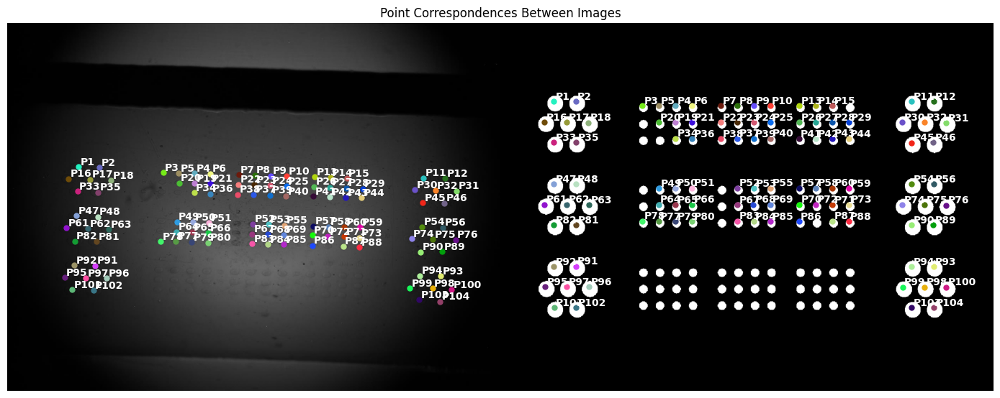

[calculate_homography] executed in 16.7524 seconds
[undistort] executed in 16.7608 seconds


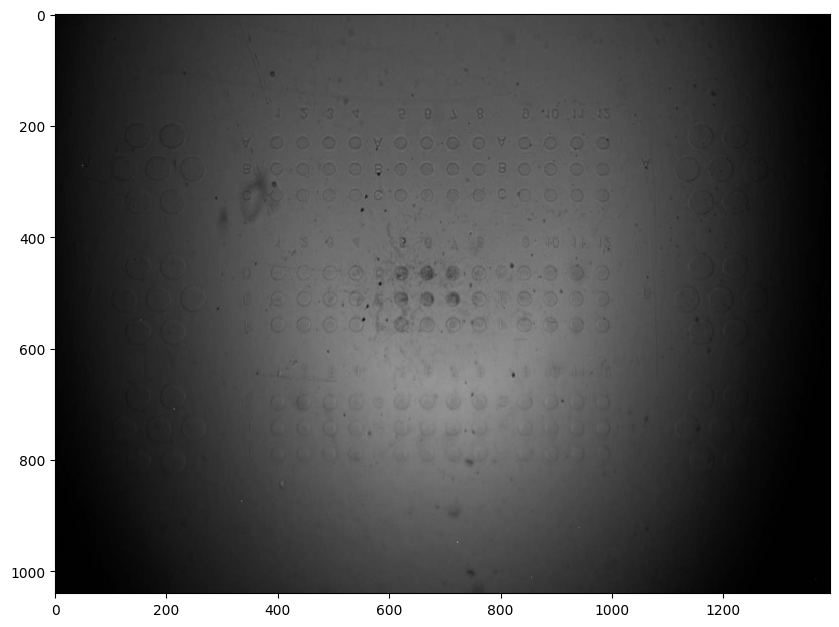

Translation: [102.1184692   45.25883707]
Scale: 0.9927007251310448
Rotation: -1.7215382507895924°


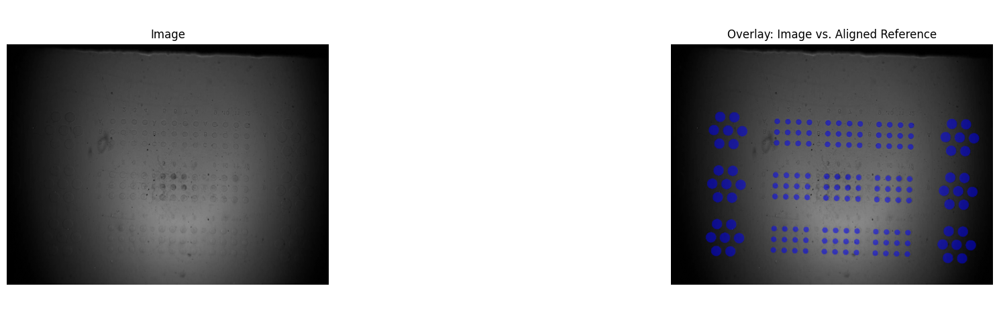

[generate_masks] executed in 8.4221 seconds
[filter_masks] executed in 1.8669 seconds
[filter_overlapping_masks] executed in 0.3022 seconds
Num overlaps:  104
[filter_overlapping_masks] executed in 0.0674 seconds
[filter_overlapping_masks] executed in 0.2347 seconds
Average IoU all: 0.7401893094931633
Average IoU large: 0
Average IoU medium: 0.7394017993196681
Average IoU small: 0.7407227841268212
[evaluate_camera_calibration] executed in 19.1817 seconds
Translation: [-6.17744401 -4.80285452]
Scale: 1.0021926103472707
Rotation: -0.0750389801682445°


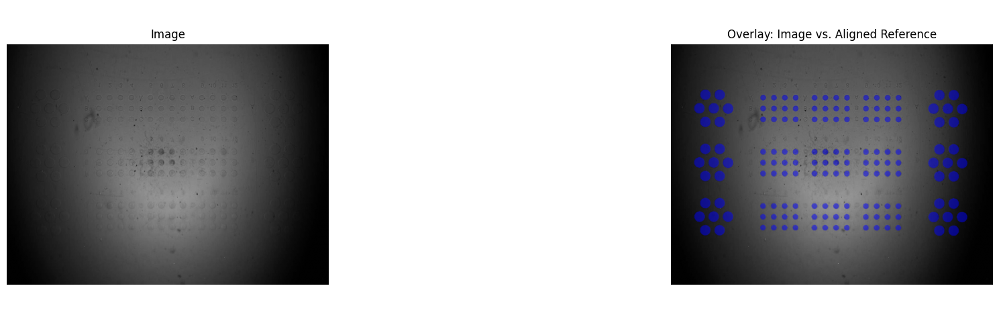

[generate_masks] executed in 7.6994 seconds
[filter_masks] executed in 1.9395 seconds
[filter_overlapping_masks] executed in 0.3739 seconds
Num overlaps:  115
[filter_overlapping_masks] executed in 0.1061 seconds
[filter_overlapping_masks] executed in 0.2717 seconds
Average IoU all: 0.8053384769518361
Average IoU large: 0
Average IoU medium: 0.8250455704901395
Average IoU small: 0.7944196818833159
[evaluate_camera_calibration] executed in 18.8796 seconds
==== Evaluating camera calibration for image 290-4-0,75x-19_-2. ====
Translation: [98.5189746  56.06141432]
Scale: 0.9927449009972432
Rotation: -1.6796301441322328°


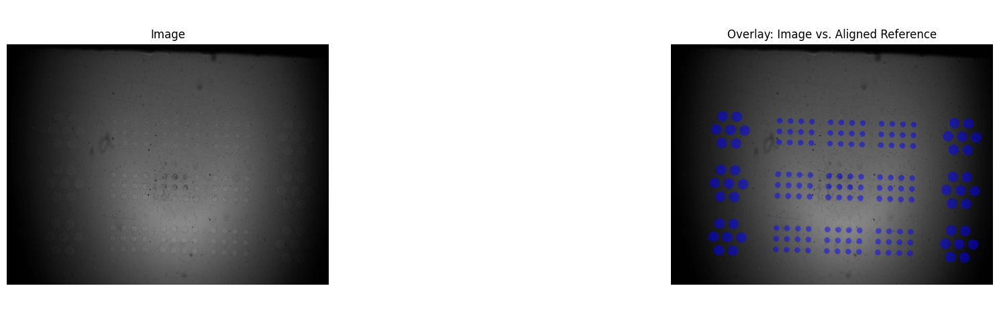

[_apply_imreg_dft] executed in 5.9775 seconds
[generate_masks] executed in 7.5256 seconds
[filter_masks] executed in 1.5769 seconds
[find_overlapping_pairs] executed in 0.3016 seconds
Src: 109, Dst: 109
[_match_centroids] executed in 9.9248 seconds


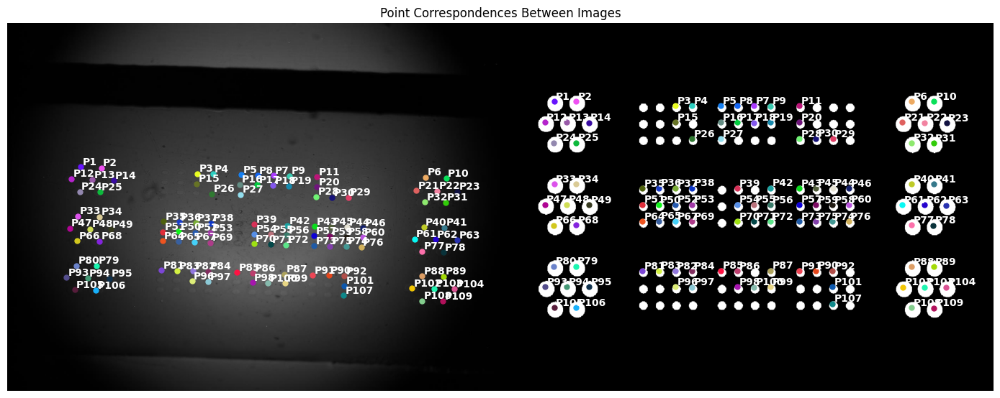

[calculate_homography] executed in 16.2791 seconds
[undistort] executed in 16.2874 seconds


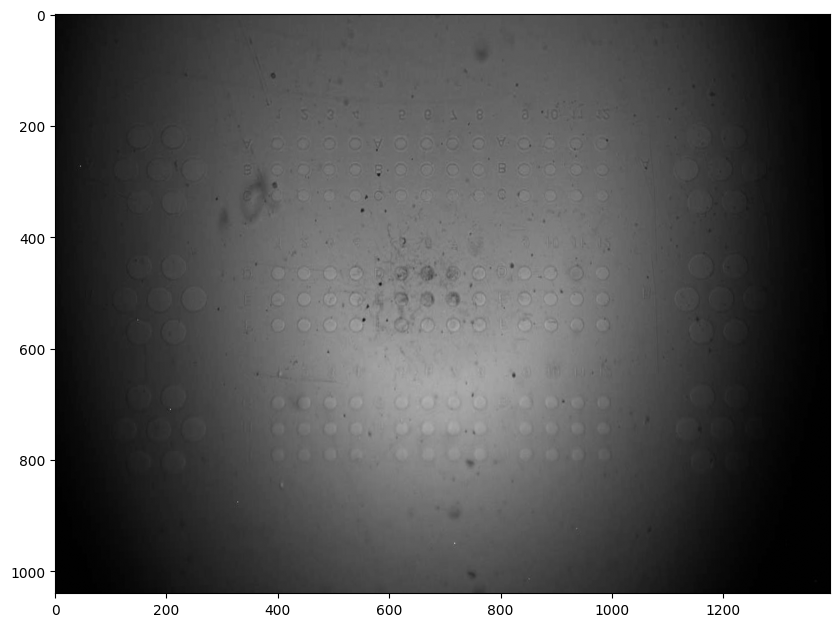

Translation: [98.5189746  56.06141432]
Scale: 0.9927449009972432
Rotation: -1.6796301441322328°


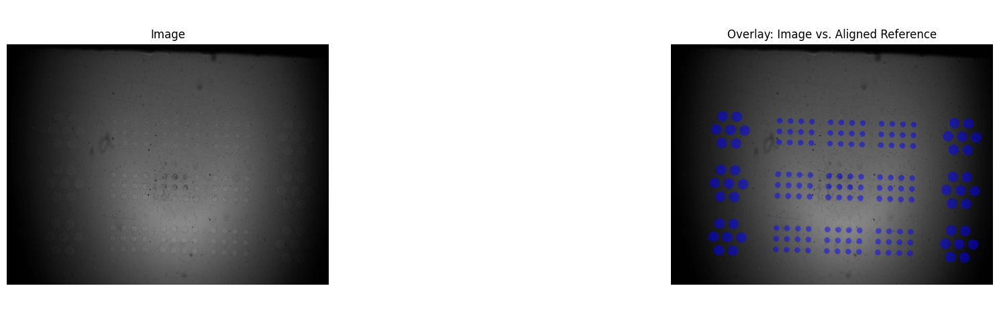

[generate_masks] executed in 7.5272 seconds
[filter_masks] executed in 1.5630 seconds
[filter_overlapping_masks] executed in 0.2984 seconds
Num overlaps:  109
[filter_overlapping_masks] executed in 0.0675 seconds
[filter_overlapping_masks] executed in 0.2054 seconds
Average IoU all: 0.6682247886461701
Average IoU large: 0
Average IoU medium: 0.75834143612531
Average IoU small: 0.6117337558980529
[evaluate_camera_calibration] executed in 18.0242 seconds
Translation: [227.62906543  -4.81465475]
Scale: 1.0006457308776515
Rotation: -0.07346932749965163°


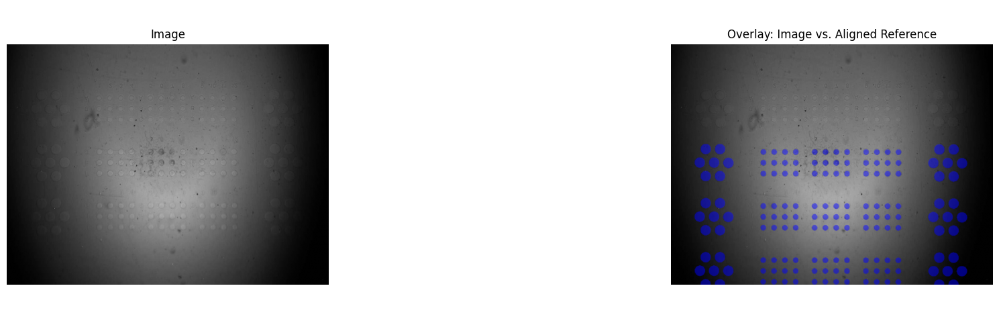

[generate_masks] executed in 7.5104 seconds
[filter_masks] executed in 1.5355 seconds
[filter_overlapping_masks] executed in 0.2288 seconds
Num overlaps:  76
[filter_overlapping_masks] executed in 0.0448 seconds
[filter_overlapping_masks] executed in 0.1645 seconds
Average IoU all: 0.7960668977326907
Average IoU large: 0
Average IoU medium: 0.8072488139256982
Average IoU small: 0.7895441132867694
[evaluate_camera_calibration] executed in 17.1471 seconds


In [4]:
df = pd.DataFrame(columns=["iou_all", "iou_large", "iou_medium", "iou_small"])

for image_data in tqdm(data):
    name = image_data["file_path"].split('/')[-1].split('.')[0]
    print(f"==== Evaluating camera calibration for image {name}. ====")
    
    # Open Image
    gray_image = np.array(Image.open(image_data["file_path"]).convert("L"))

    corrected, affine = calibrator.undistort(
        gray_image,
        chip_region=EXPERIMENT_CONFIG["chip_region"],
        debug=EXPERIMENT_CONFIG["debug"]
    )
    
    plt.figure(figsize=(10,10))
    plt.imshow(corrected, cmap='gray')
    plt.show()

    iou_all, iou_large, iou_medium, iou_small = evaluate_camera_calibration(
        image=affine, 
        ref_image=calibrator.ref_image, 
        segmenter=segmenter, 
        debug=EXPERIMENT_CONFIG["debug"]
    )
    df.loc[len(df)] = [iou_all, iou_large, iou_medium, iou_small]

    iou_all, iou_large, iou_medium, iou_small = evaluate_camera_calibration(
        image=corrected, 
        ref_image=calibrator.ref_image, 
        segmenter=segmenter, 
        debug=EXPERIMENT_CONFIG["debug"]
    )
    df.loc[len(df)] = [iou_all, iou_large, iou_medium, iou_small]


In [5]:
print(df)

     iou_all  iou_large  iou_medium  iou_small
0   0.636741        0.0    0.684207   0.618282
1   0.879562        0.0    0.898446   0.872218
2   0.628959        0.0    0.700115   0.601288
3   0.855227        0.0    0.892899   0.840577
4   0.579533        0.0    0.696478   0.534054
5   0.828433        0.0    0.833003   0.826655
6   0.738699        0.0    0.772401   0.725593
7   0.838189        0.0    0.867491   0.826793
8   0.662759        0.0    0.715112   0.641817
9   0.836641        0.0    0.885341   0.817525
10  0.710608        0.0    0.787381   0.678682
11  0.845229        0.0    0.908290   0.820369
12  0.740758        0.0    0.770382   0.725009
13  0.820812        0.0    0.825540   0.818199
14  0.740189        0.0    0.739402   0.740723
15  0.805338        0.0    0.825046   0.794420
16  0.668225        0.0    0.758341   0.611734
17  0.796067        0.0    0.807249   0.789544


In [6]:
import pandas as pd
import numpy as np

import pandas as pd

def save_df_with_even_odd_averages(df, filename='output.csv'):
    # Select even and odd rows by index
    even_rows = df.iloc[::2]   # rows 0, 2, 4, ...
    odd_rows = df.iloc[1::2]   # rows 1, 3, 5, ...

    # Compute averages (numeric columns only)
    even_avg = even_rows.mean(numeric_only=True)
    odd_avg = odd_rows.mean(numeric_only=True)

    # Label the rows
    even_avg.name = 'average_even_rows'
    odd_avg.name = 'average_odd_rows'

    # Print the averages
    print("Average of even-indexed rows:")
    print(even_avg)
    print("Average of odd-indexed rows:")
    print(odd_avg)

    # Append to DataFrame
    df_with_averages = pd.concat([df, even_avg.to_frame().T, odd_avg.to_frame().T], axis=0)

    # Save to CSV
    df_with_averages.to_csv(filename, index=True)

    return df_with_averages

result = save_df_with_even_odd_averages(df)

Average of even-indexed rows:
iou_all       0.678497
iou_large     0.000000
iou_medium    0.735980
iou_small     0.653020
Name: average_even_rows, dtype: float64
Average of odd-indexed rows:
iou_all       0.833944
iou_large     0.000000
iou_medium    0.860367
iou_small     0.822922
Name: average_odd_rows, dtype: float64
